# 三篇新的金融计量论文：本地核心实验复现

本次选择我们尚未复现过的三篇论文，运行作者公开代码并保留原始数据、固定提交、日志、数值和图表。之前的 FDR-in-Finance 不计入这三篇。

| 论文 | 近期版本 | 本次复现范围 |
|---|---|---|
| [How to Use the Sharpe Ratio](https://ssrn.com/abstract=5520741) | 2025-10-04 发布；2026-03-25 修订 | 作者数值例子；Exhibit 2 全部 2,000 组、每组 10,000 条路径 |
| [Stripping the Discount Curve—A Robust Machine Learning Approach](https://doi.org/10.1287/mnsc.2023.01401) | 2025-12-22 在线发表；2026 年期刊卷期 | 作者公开的两个日期国债样本；核岭回归曲线估计 |
| [Shrinking the Term Structure](https://ssrn.com/abstract=4182649) | Review of Finance，2026-08-21 在线发表；最初工作论文为 2022 年 | 作者两个日期样本；期限结构收益与低秩因子模型 |

这两篇国债论文由 Damir Filipović、Markus Pelger、Ye Ye 撰写，属于同一研究路线。夏普比率论文作者为 Marcos López de Prado、Alexander Lipton、Vincent Zoonekynd。

**复现边界：**这里复现公开核心实验。国债样本不能代替全历史样本的样本外检验；完整历史数据需要 WRDS/CRSP。夏普作者代码固定于 2026-02-05，早于 3 月论文修订，未取得新版全文做逐图核对。它的模拟生成器采用 Gaussian copula 加混合分布边际，方差公式在这里是近似；图表会直接展示近似偏差。

来源：[作者 Stanford 数据与代码页](https://mpelger.people.stanford.edu/data-and-code)，[夏普作者仓库](https://github.com/zoonek/2025-sharpe-ratio)，[国债曲线仓库](https://github.com/yye9701/KR_example)，[国债收益仓库](https://github.com/rosieiiiii/KR_return_example)。

In [1]:
# STEP_1 环境检查与可复现运行工具
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import sys, os, json, hashlib, subprocess, time
import importlib.metadata as metadata
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
root = Path.cwd()
assert (root / 'setup_sources.py').exists(), 'Launch Jupyter from the repository directory.'
assert sys.version_info >= (3, 11)
print('运行时间:', datetime.now(ZoneInfo('Asia/Shanghai')).isoformat(timespec='seconds'))
print('Python:', sys.version.split()[0], Path(sys.executable).name)
versions = {p: metadata.version(p) for p in ['numpy','pandas','scipy','matplotlib','scikit-learn']}
print('依赖版本:', versions)
print('依赖按 requirements.txt 安装。')

def run_project(name, *arguments):
    project = root / name
    env = dict(os.environ)
    env.update(PYTHONUNBUFFERED='1', MPLBACKEND='Agg',
               MPLCONFIGDIR=str(project / '.mplconfig'),
               OMP_NUM_THREADS='1', OPENBLAS_NUM_THREADS='1', VECLIB_MAXIMUM_THREADS='1')
    command = [sys.executable, '-u', str(project / 'replication_runner.py'), *arguments]
    print('开始运行:', name, ' '.join(arguments), flush=True)
    log_dir = project / 'results'
    log_dir.mkdir(exist_ok=True)
    with (log_dir / ('jupyter_' + ('_'.join(arguments).replace('--','') or 'full') + '.log')).open('w') as log:
        process = subprocess.Popen(command, cwd=project, env=env, stdout=subprocess.PIPE,
                                   stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in process.stdout:
            log.write(line); log.flush()
            print(line, end='', flush=True)
        status = process.wait()
    assert status == 0, f'{name} failed with exit {status}'
    return json.loads((project / 'results' / 'summary.json').read_text())

def show_saved_image(project, filename, width=1100):
    display(Image(filename=str(root / project / 'results' / filename), width=width))

print('STEP 1 完成：环境正常。')

运行时间: 2026-10-15T20:22:45+08:00
Python: 3.14.6 python
依赖版本: {'numpy': '2.4.6', 'pandas': '3.0.3', 'scipy': '1.18.0', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
依赖按 requirements.txt 安装。
STEP 1 完成：环境正常。


## 夏普比率：作者数值例子与独立公式核验

沿用作者输入：24 个月、收益均值 0.036、标准差 0.079、偏度 −2.448、峰度 10.164；比较自相关 0 和 0.2。运行作者的推断检验和完整数值例子，并独立核对单策略方差、PSR、贝叶斯 FDR 控制结果。作者打印的 MinTRL 使用 10% 单边显著性水平，单位为月。

In [2]:
# STEP_2 作者夏普比率数值例子
sharpe_summary = run_project('sharpe_ratio_inference', '--mode', 'numeric')
numeric = pd.read_csv(root / 'sharpe_ratio_inference/results/numeric_example.csv')
display(numeric.round(6))
assert sharpe_summary['numeric_example']['independent_formula_check_passed']
print('STEP 2 完成：作者检验与独立公式检查通过。')

开始运行: sharpe_ratio_inference --mode numeric


Author source hashes verified: 6199ecb1c84da7eee7bd81d9a017cf12b8ff0e0d


Author inference tests passed: 7


----------


SR0                    = 0.000


...

β (K=1)              = 0.797


SR_c (K=1)           = 1.452


Saved results/summary.json | status=partial


,rho,observed_monthly_SR,generalized_standard_error,gaussian_iid_standard_error,minimum_track_record_months,PSR,p_value,power,planned_FDR,FDR_controlled_critical_SR,target_FDR,achieved_FDR,variance_formula_absolute_error
0,0.0,0.455696,0.328589,0.21446,7.908996,0.987207,0.012793,0.757531,0.542976,0.409640,0.25,0.25,0.0
1,0.2,0.455696,0.379490,0.21446,11.863494,0.965832,0.034168,0.676292,0.570960,0.527089,0.25,0.25,0.0


STEP 2 完成：作者检验与独立公式检查通过。


## 夏普比率：Exhibit 2 主模拟块完整网格

从原始 Notebook 提取 `f3` 的计算体，仅去掉 Ray 装饰器，以顺序执行显示进度。保持作者参数：T=60、每组 10,000 条路径、5 个每期 SR、100 个 rho、4 种边际分布，共 2,000 组。额外指定随机种子 20261015（原 Notebook 没有固定种子），故不声称与作者未固定的随机抽样逐位一致。

`rho` 是作者生成器参数；经过非线性边际变换后，非正态收益的实际 Pearson 自相关可能不同。公式近似误差会记录在 CSV，不以模拟线与公式完全相等作为成功条件。

In [3]:
# STEP_3 运行作者 Exhibit 2 主模拟块完整网格
sharpe_summary = run_project('sharpe_ratio_inference', '--mode', 'exhibit2')
assert sharpe_summary['status'] == 'completed'
assert sharpe_summary['exhibit2']['cases'] == 2000
print('STEP 3 完成：2,000 组模拟全部结束。')

开始运行: sharpe_ratio_inference --mode exhibit2


Author source hashes verified: 6199ecb1c84da7eee7bd81d9a017cf12b8ff0e0d


Exhibit 2 full grid: 2000 cases, T=60, 10,000 paths/case, seed=20261015


Completed 100/2000 | 12.9s


Completed 200/2000 | 25.9s


...

Completed 1800/2000 | 232.5s


Completed 1900/2000 | 245.3s


Completed 2000/2000 | 258.5s


Saved results/summary.json | status=completed


STEP 3 完成：2,000 组模拟全部结束。


,distribution,formula,median_absolute_relative_error,max_absolute_relative_error
0,gaussian,Gaussian iid,0.4252,0.6918
1,gaussian,Gaussian + autocorrelation,0.0607,0.1226
2,gaussian,Non-Gaussian iid,0.4239,0.6918
3,gaussian,Non-Gaussian + autocorrelation,0.0604,0.1169
4,mild,Gaussian iid,0.5441,0.7762
5,mild,Gaussian + autocorrelation,0.2477,0.4413
6,mild,Non-Gaussian iid,0.3926,0.6898
7,mild,Non-Gaussian + autocorrelation,0.0519,0.0999
8,moderate,Gaussian iid,0.6337,0.8284
9,moderate,Gaussian + autocorrelation,0.3797,0.6396


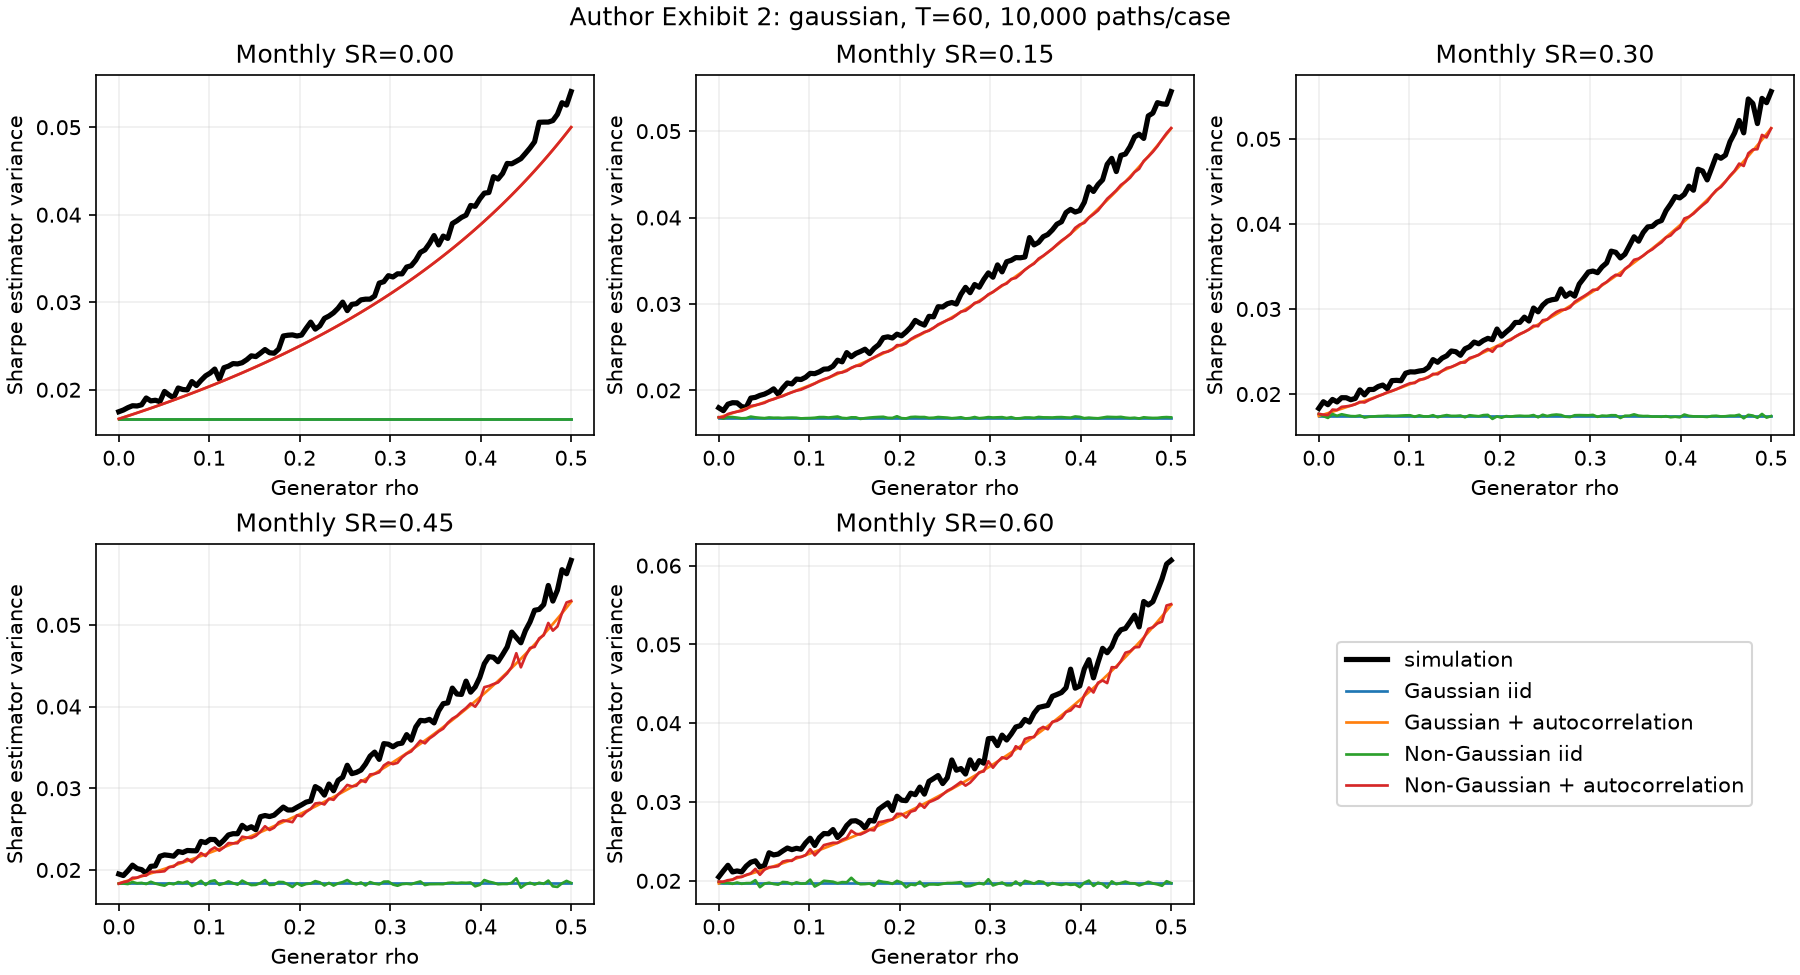

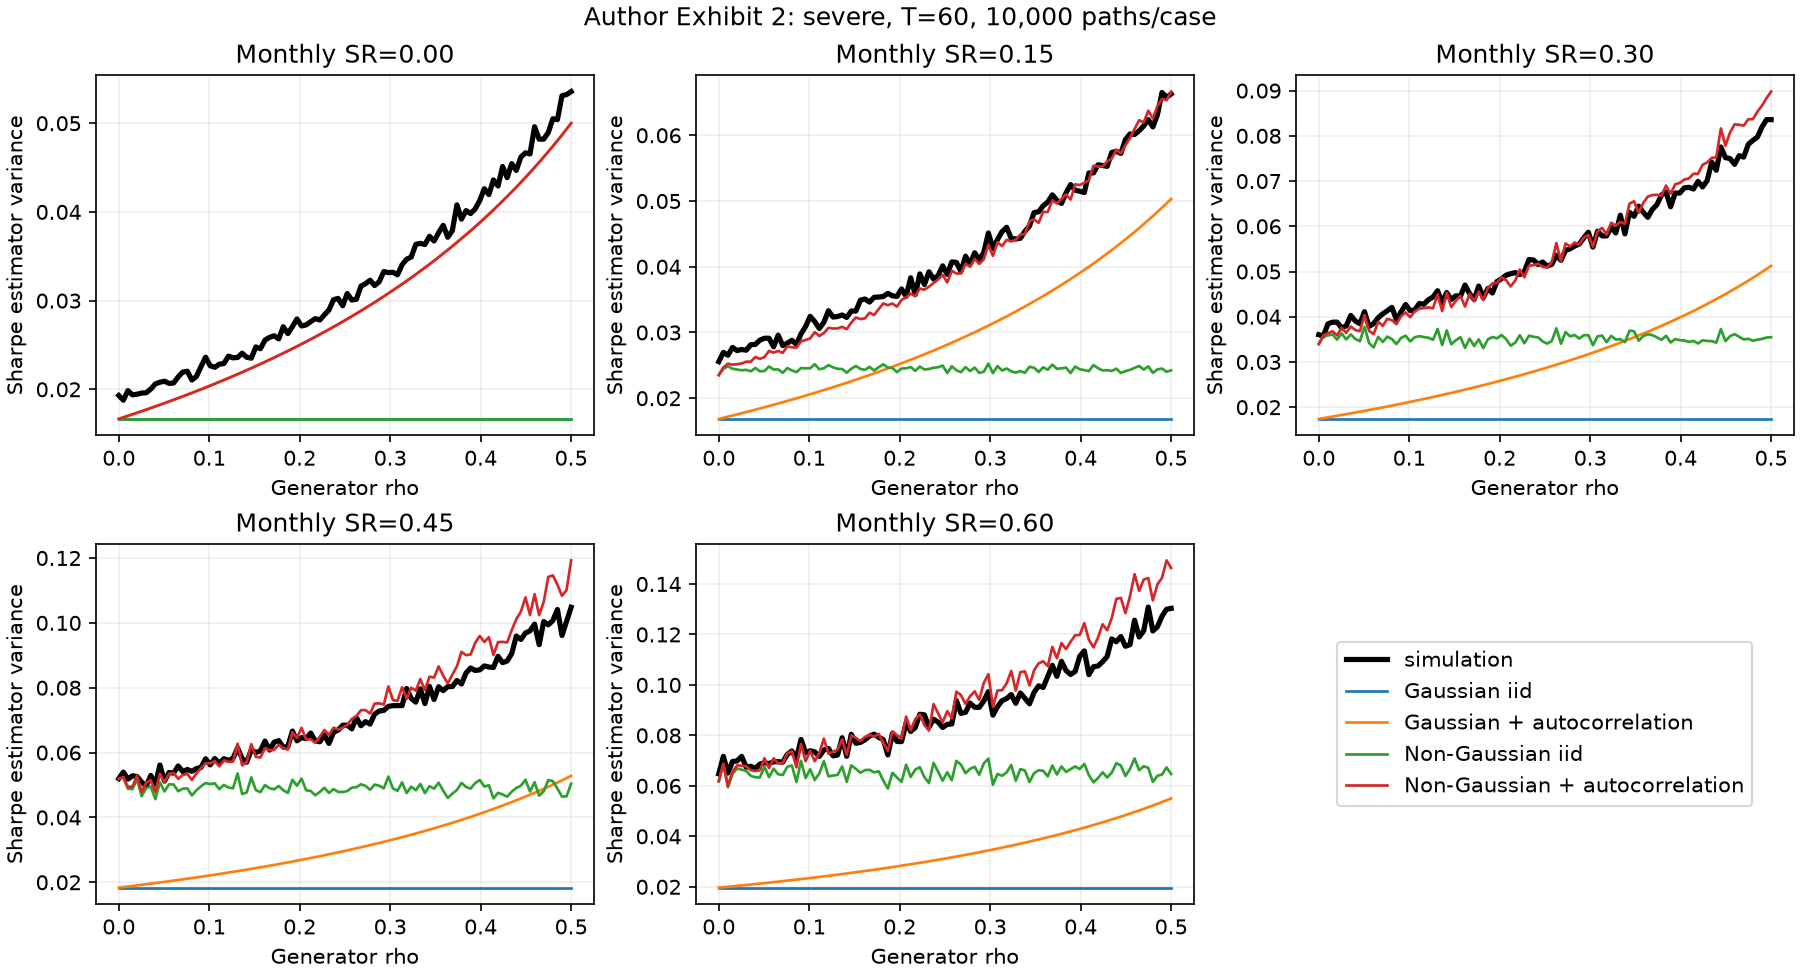

STEP 4 完成：保留模拟偏差，结果不等于对所有收益过程的理论证明。


In [4]:
# STEP_4 夏普模拟图与近似误差
errors = pd.read_csv(root / 'sharpe_ratio_inference/results/exhibit2_approximation_errors.csv')
display(errors.round(4))
show_saved_image('sharpe_ratio_inference', 'exhibit2_gaussian.png')
show_saved_image('sharpe_ratio_inference', 'exhibit2_severe.png')
print('STEP 4 完成：保留模拟偏差，结果不等于对所有收益过程的理论证明。')

## 国债折现曲线：Stripping the Discount Curve

运行作者核岭回归和原始逐日 30 年期限网格，样本日期为 1961-06-30、2013-12-31。展示折现/收益率曲线、观测与拟合债券价格和收益率，并核对闭式解、核函数及到期收益率计算。这里的拟合误差属于公开样本的样本内误差，不能据此验证论文全历史样本外优势。

开始运行: stripping_discount_curve 


Matplotlib is building the font cache; this may take a moment.


[Stripping] Original source hashes verified; loading real bundled Treasury data.


  1961-06-30: 50 bonds; maximum maturity 6.879 years


  2013-12-31: 280 bonds; maximum maturity 29.389 years


...

[Stripping] Estimating both dates with unmodified authors' KR().


  1961-06-30: yield RMSE 6.735666 bps; relative pricing RMSE 14.935929 bps


  2013-12-31: yield RMSE 1.687168 bps; relative pricing RMSE 4.974404 bps


[Stripping] All numerical checks passed. Saved summary.json and 3 plots; 3.6 seconds.


,date,securities,max_maturity_years,price_rmse,relative_price_rmse_bps,yield_rmse_bps,yield_mae_bps,discount_positive_within_observed_maturities
0,1961-06-30,50,6.879452,0.146362,14.935929,6.735666,5.258573,True
1,2013-12-31,280,29.389041,0.056600,4.974404,1.687168,1.195806,True


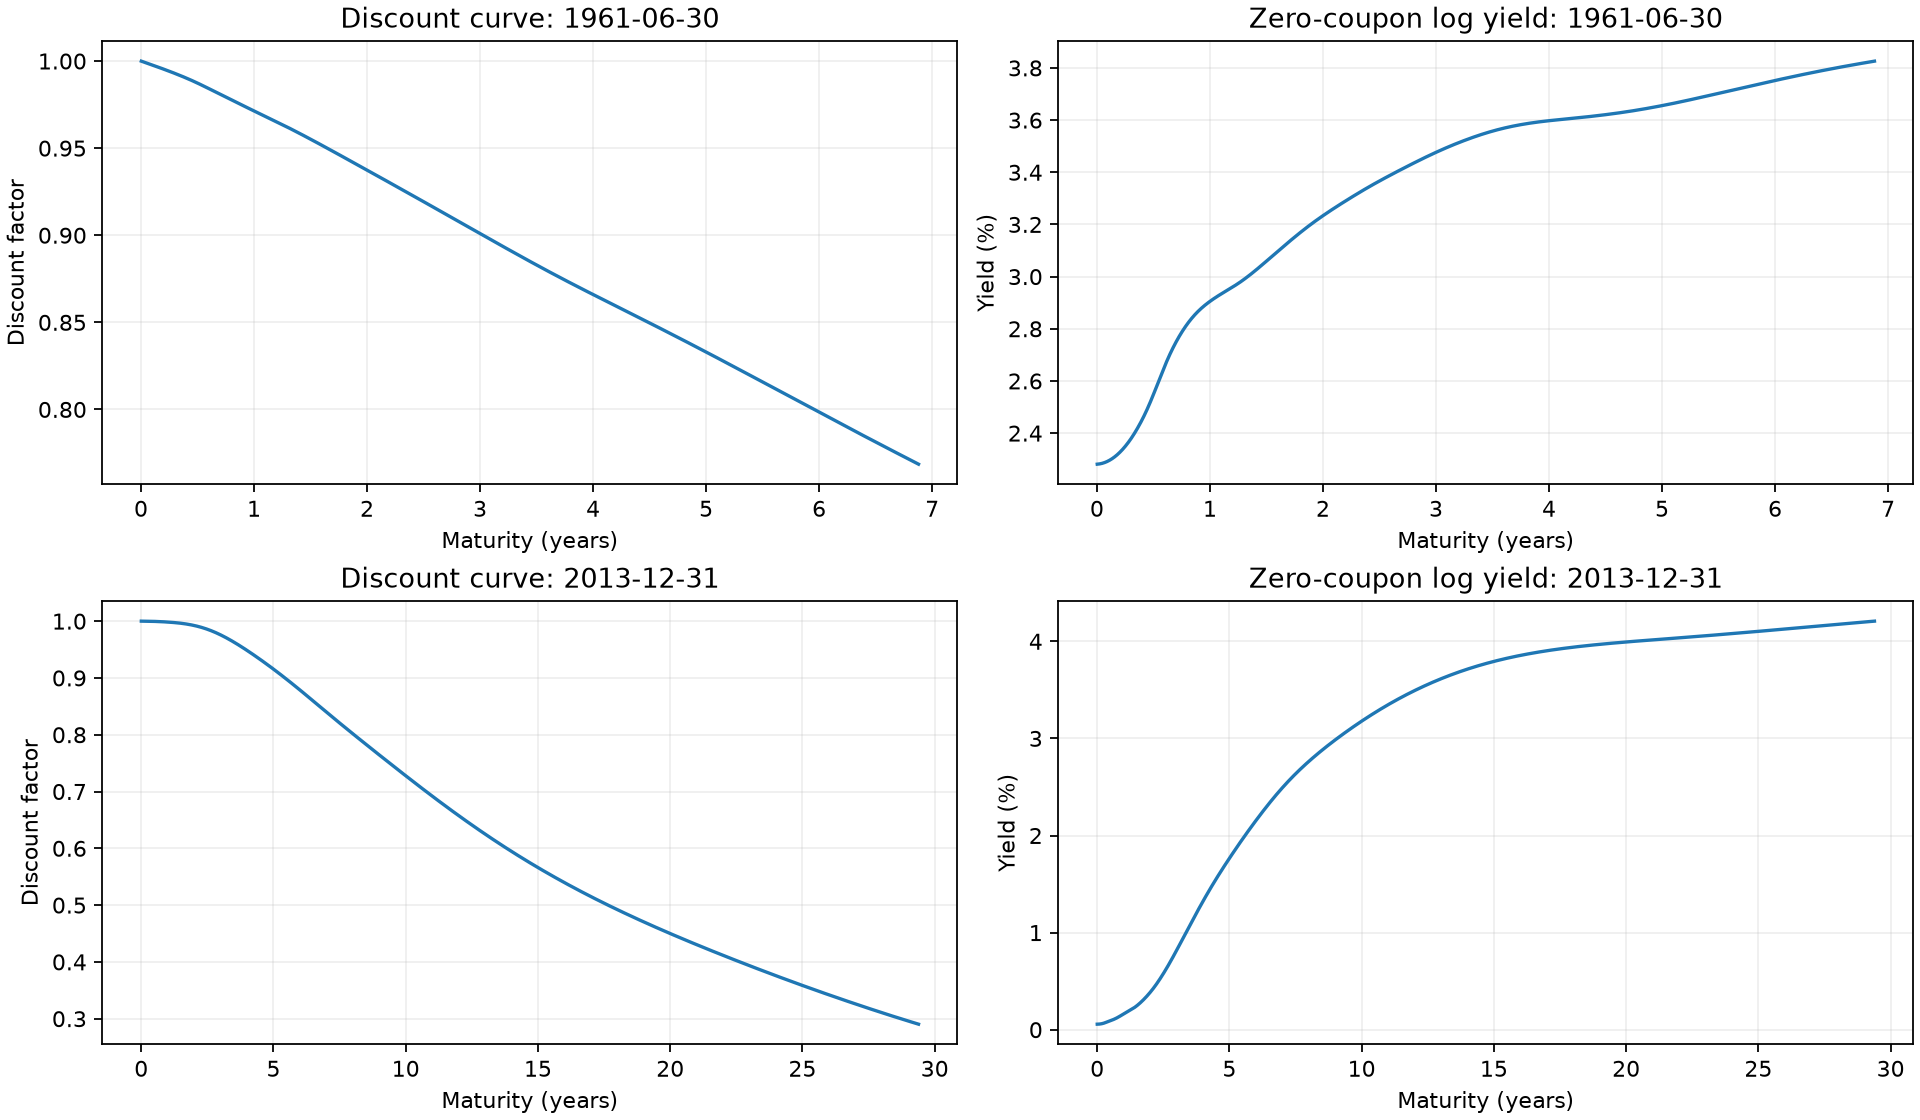

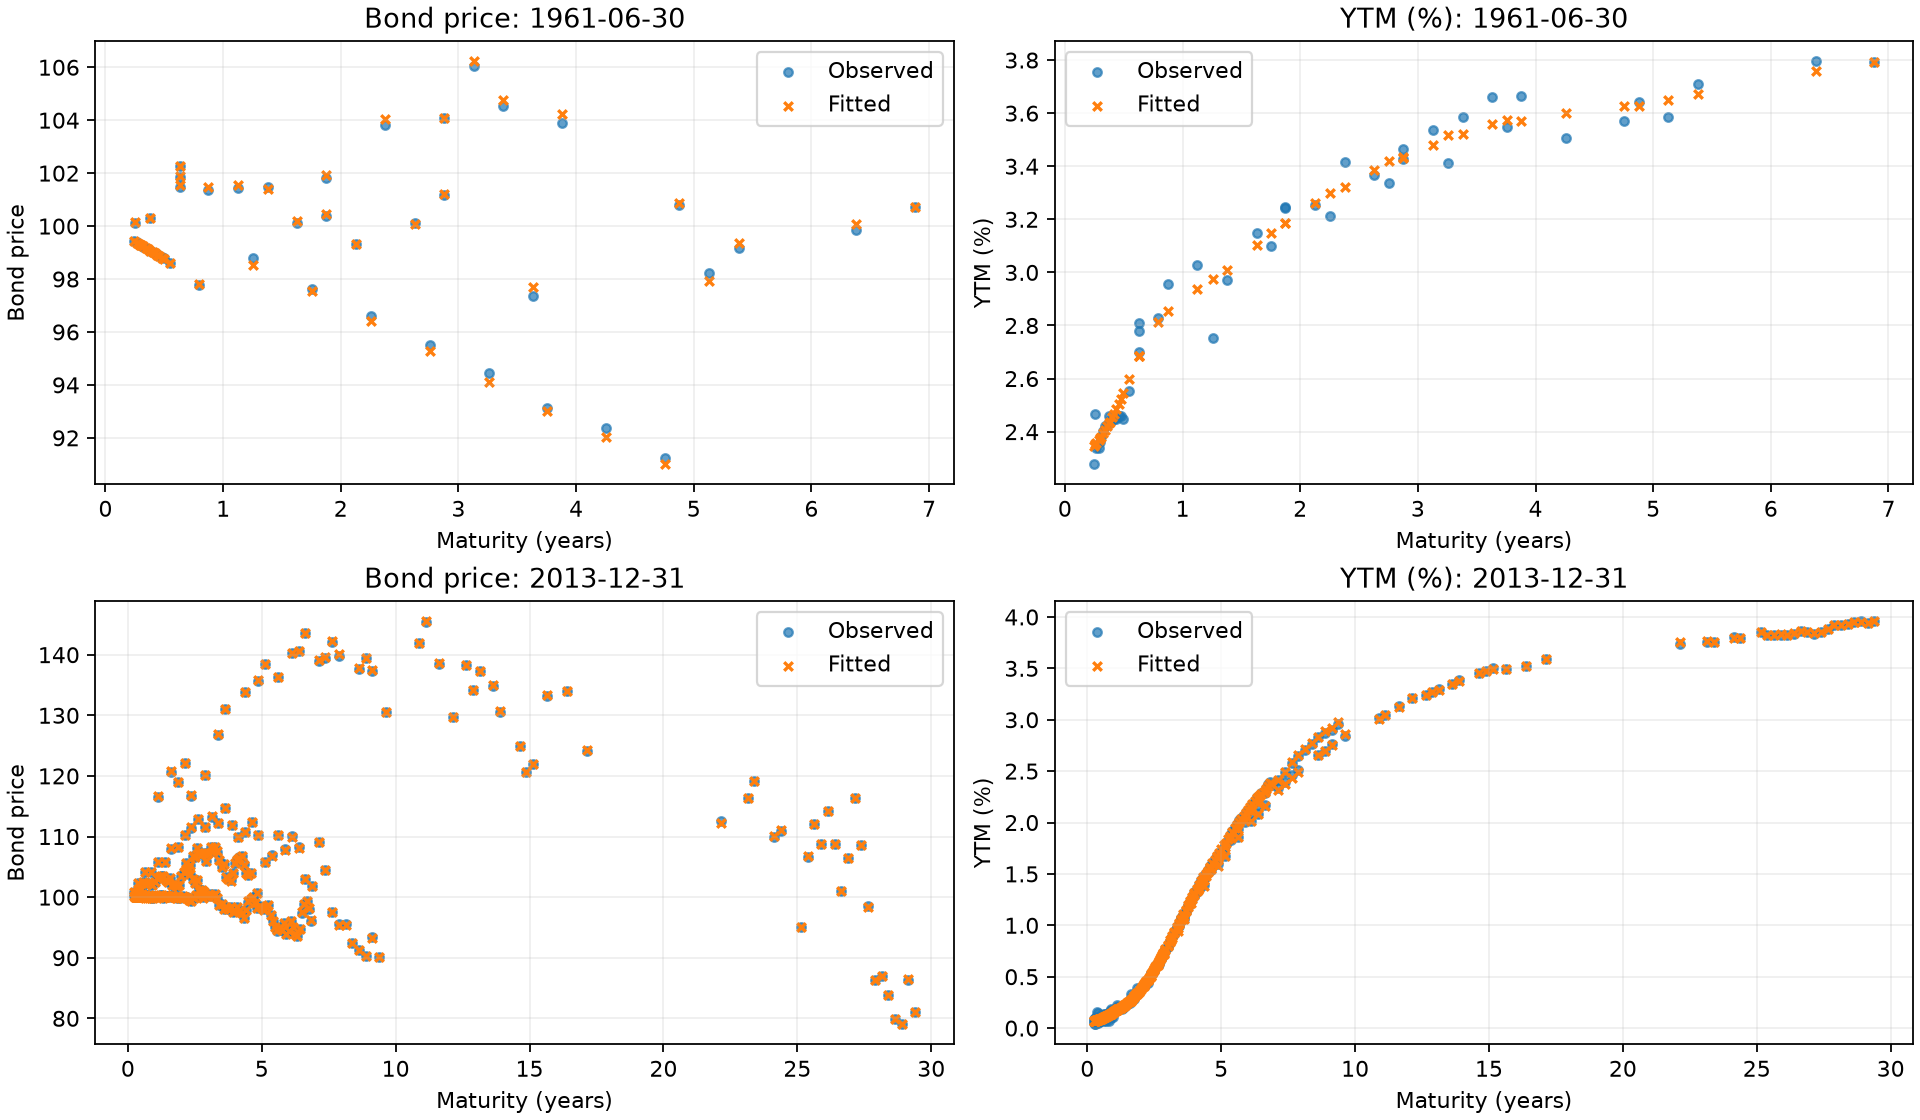

STEP 5 完成：两个日期国债曲线拟合及独立数值检查通过。


In [5]:
# STEP_5 运行作者国债折现曲线样本
stripping_summary = run_project('stripping_discount_curve')
display(pd.read_csv(root / 'stripping_discount_curve/results/metrics.csv').round(6))
assert stripping_summary['all_checks_passed']
show_saved_image('stripping_discount_curve', 'discount_yield_curves.png')
show_saved_image('stripping_discount_curve', 'observed_fitted_prices_yields.png')
print('STEP 5 完成：两个日期国债曲线拟合及独立数值检查通过。')

## 国债收益因子：Shrinking the Term Structure

运行作者附带的 1986-06-30、2013-12-31 两个真实横截面，估计完整核岭模型以及 rank=1–10 的降秩模型。核对作者解和独立线性代数表达式。完整论文的因子、套利和长样本检验还需要完整历史数据。

开始运行: shrinking_term_structure 


Matplotlib is building the font cache; this may take a moment.


[1/5] Verify fixed-commit source hashes and load two real Treasury panels


        1986-06-30: 140 bonds; 2013-12-31: 239 bonds


[2/5] Author kernel: alpha=.05, delta=0, maturity grid=3650 days


...

COMPLETE: all source, kernel, full-fit and LOOCV checks passed; 27.7 sec


model_metrics.csv


,date,model,factors,bonds,rmse_in_sample_bp,r2_uncentered_in_sample,rmse_leave_one_bond_out_bp
0,1986-06-30,Full KR,3650,140,3.972751,0.653907,4.291712
1,1986-06-30,KR-1,1,140,6.329784,0.121407,NaN
2,1986-06-30,KR-2,2,140,4.976047,0.457026,NaN
3,1986-06-30,KR-3,3,140,4.829337,0.488572,NaN
4,1986-06-30,KR-4,4,140,4.424892,0.570646,4.675869
5,1986-06-30,KR-5,5,140,4.318183,0.591105,NaN
6,1986-06-30,KR-6,6,140,4.106442,0.630222,NaN
7,1986-06-30,KR-7,7,140,4.083997,0.634253,NaN
8,1986-06-30,KR-8,8,140,4.042868,0.641583,NaN
9,1986-06-30,KR-9,9,140,4.012626,0.646925,NaN


validation.csv


,date,test,max_absolute_difference,passed
0,1986-06-30,exact LOOCV versus author estimator (Full KR),0.0,True
1,1986-06-30,exact LOOCV versus author estimator (KR-4),0.0,True
2,1986-06-30,author inverse versus independent positive-def...,0.0,True
3,2013-12-31,exact LOOCV versus author estimator (Full KR),0.0,True
4,2013-12-31,exact LOOCV versus author estimator (KR-4),0.0,True
5,2013-12-31,author inverse versus independent positive-def...,0.0,True


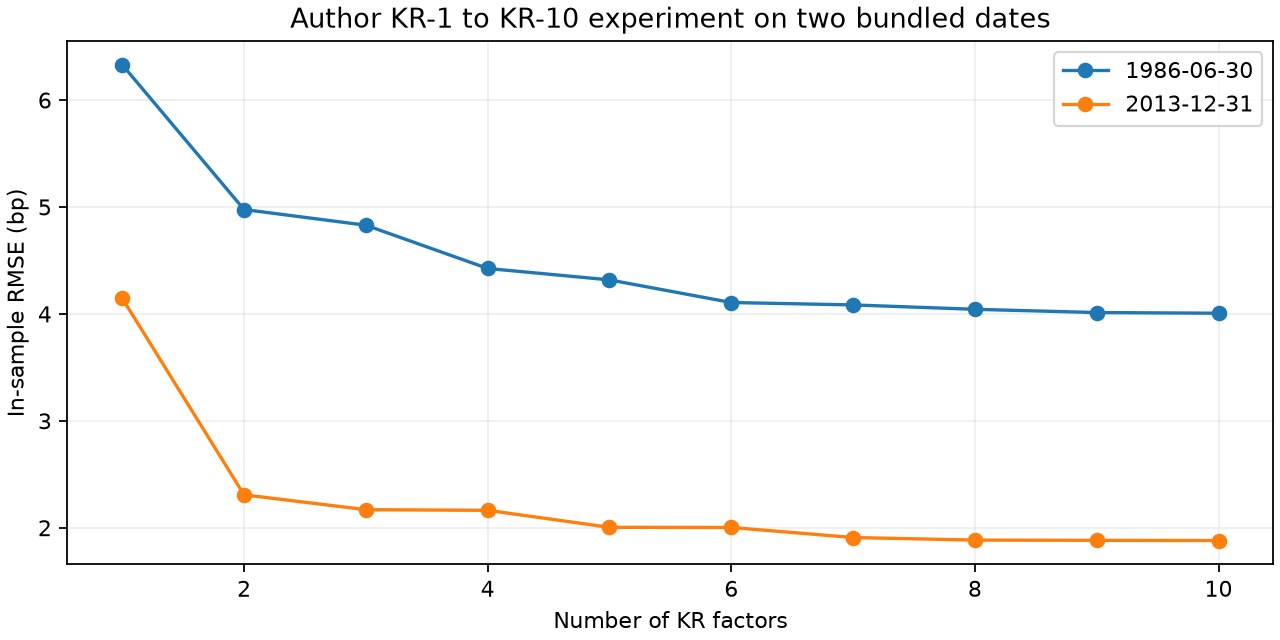

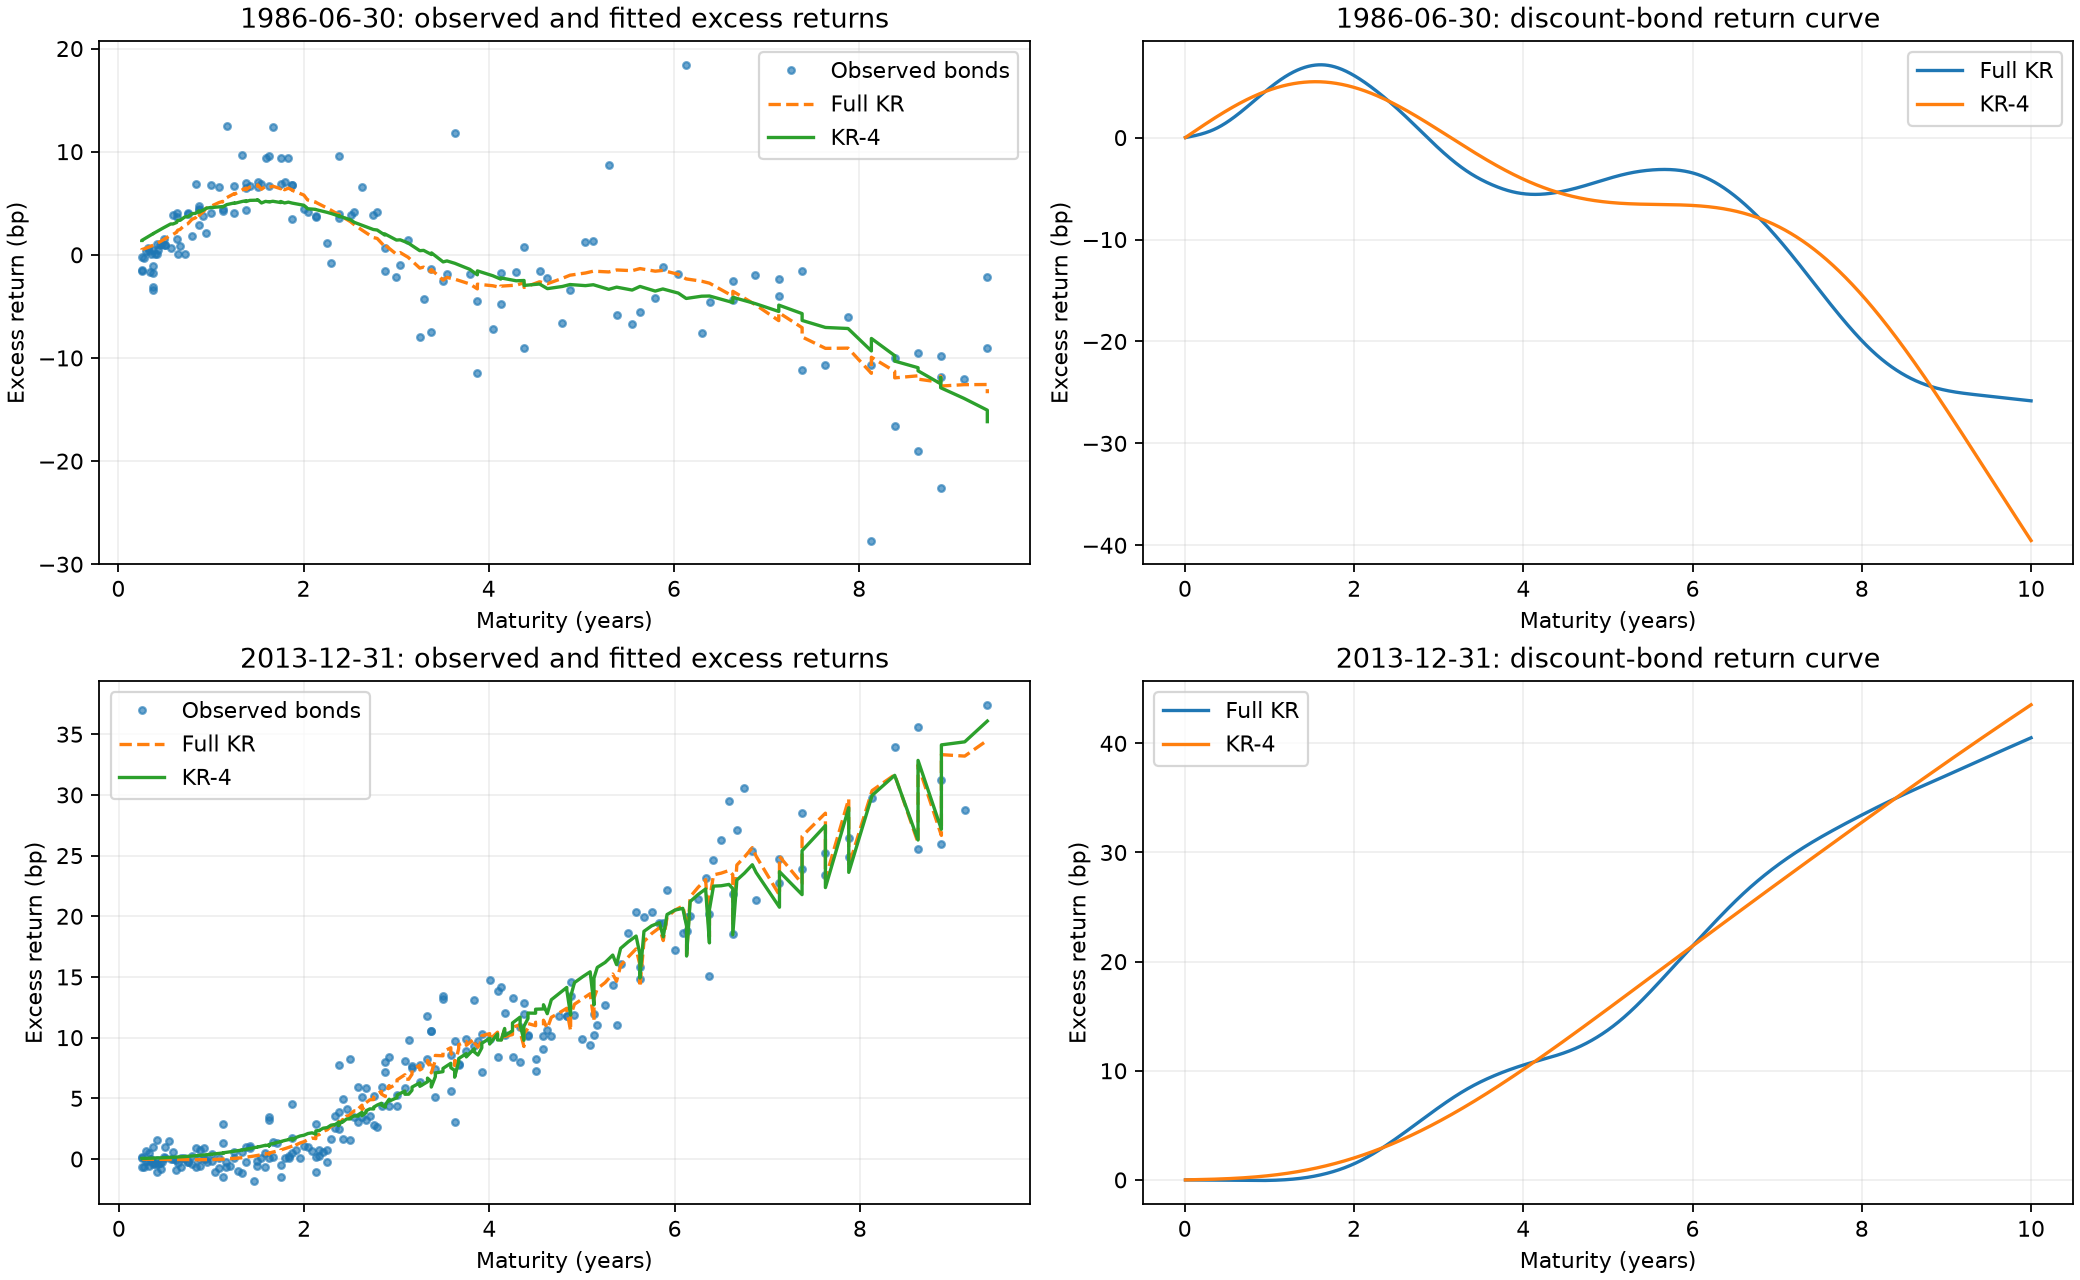

STEP 6 完成：两个日期的国债收益模型已运行。


In [6]:
# STEP_6 运行作者国债收益与低秩因子模型
shrinking_summary = run_project('shrinking_term_structure')
assert shrinking_summary['validation_passed']
for path in sorted((root / 'shrinking_term_structure/results').glob('*.csv')):
    if 'prediction' not in path.name and 'curve' not in path.name:
        print(path.name)
        display(pd.read_csv(path).head(22).round(6))
for path in sorted((root / 'shrinking_term_structure/results').glob('*.png')):
    if 'author' not in path.name:
        display(Image(filename=str(path), width=1100))
print('STEP 6 完成：两个日期的国债收益模型已运行。')

## 运行记录与复现边界

三个项目各自保存 `source_manifest.json`、作者源码、`paper_metadata.json`、运行器、日志、CSV、PNG 和 `results/summary.json`。重新运行上面的单元格即可在这台 Anaconda 电脑上再次执行。

In [7]:
# STEP_7 汇总三个项目
summaries = {name: json.loads((root / name / 'results/summary.json').read_text())
             for name in ['sharpe_ratio_inference','stripping_discount_curve','shrinking_term_structure']}
report = {'executed_at': datetime.now(ZoneInfo('Asia/Shanghai')).isoformat(timespec='seconds'),
          'interpreter': Path(sys.executable).name, 'versions': versions, 'projects': summaries,
          'scope': 'Three author-code core experiments; not full-paper reproduction of every empirical table.'}
(root / 'replication_summary.json').write_text(json.dumps(report, ensure_ascii=False, indent=2))
display(Markdown('**三篇核心实验已完成，日志、数值和图表已保存。**'))
print('1. 夏普比率：作者数值例子 + 完整 Exhibit 2 网格；近似误差直接报告。')
print('2. 国债折现：两日期作者真实样本 + 独立数值核验。')
print('3. 国债收益：两日期作者真实样本 + rank 1–10 模型。')
print('若要验证两篇国债论文的全历史样本外结论，下一步需要获得 WRDS/CRSP 数据访问权限。')
print('STEP 7 完成。')

**三篇核心实验已完成，日志、数值和图表已保存。**

1. 夏普比率：作者数值例子 + 完整 Exhibit 2 网格；近似误差直接报告。
2. 国债折现：两日期作者真实样本 + 独立数值核验。
3. 国债收益：两日期作者真实样本 + rank 1–10 模型。
若要验证两篇国债论文的全历史样本外结论，下一步需要获得 WRDS/CRSP 数据访问权限。
STEP 7 完成。
